## Load the libraries

In [1]:
import torch 
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
import torch.optim as optim
import deepguard
from deepguard import ms_eff_gcvit_b0
import timm
from pathlib import Path
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

## Load dataset

In [2]:
real_dir = Path(
    r"D:\Projects\Deepfake detection\datasets\videos\original_sequences\youtube\c23\videos"
)

fake_dir = Path(
    r"D:\Projects\Deepfake detection\datasets\videos\manipulated_sequences\Deepfakes\c23\videos"
)

real_videos = list(real_dir.glob("*.mp4"))
fake_videos = list(fake_dir.glob("*.mp4"))

print("Real videos:", len(real_videos))
print("Fake videos:", len(fake_videos))

print("\nSample real video:", real_videos[0].name if real_videos else "None")
print("Sample fake video:", fake_videos[0].name if fake_videos else "None")

Real videos: 200
Fake videos: 200

Sample real video: 004.mp4
Sample fake video: 004_982.mp4


Video opened: True
Total frames: 309
FPS: 25.0


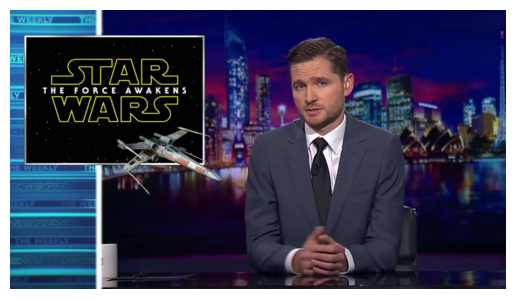

In [3]:
video_path = str(real_videos[0])

cap = cv.VideoCapture(video_path)

print("Video opened:", cap.isOpened())
print("Total frames:", int(cap.get(cv.CAP_PROP_FRAME_COUNT)))
print("FPS:", cap.get(cv.CAP_PROP_FPS))

ret, frame = cap.read()

if ret:
    frame = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
    plt.imshow(frame)
    plt.axis("off")
    plt.show()
else:
    print("Could not read a frame.")

cap.release()

In [4]:
def extract_frames(video_path, num_frames=16):
    cap = cv.VideoCapture(str(video_path))

    total_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))

    if not cap.isOpened() or total_frames == 0:
        cap.release()
        raise ValueError(f"Cannot read video: {video_path}")

    indices = np.linspace(
        0, total_frames - 1, num_frames, dtype=int
    )

    frames = []

    for idx in indices:
        cap.set(cv.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()

        if ret:
            frame = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
            frames.append(frame)

    cap.release()

    return frames

sample_frames = extract_frames(real_videos[0])

print("Frames extracted:", len(sample_frames))
print("Frame shape:", sample_frames[0].shape if sample_frames else None)

Frames extracted: 16
Frame shape: (720, 1280, 3)


In [5]:
IMG_SIZE = 299

transform = transforms.Compose(
    [
        transforms.ToPILImage(),
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
    ]
)

frame_tensor = transform(sample_frames[0])

print("Transformed frame shape:", frame_tensor.shape)
print("Data type:", frame_tensor.dtype)

Transformed frame shape: torch.Size([3, 299, 299])
Data type: torch.float32


In [6]:
class DeepfakeVideoDataset(Dataset):
    def __init__(self, real_videos, fake_videos, transform, num_frames=16):
        self.video_paths = (
            [(path, 0) for path in real_videos] +
            [(path, 1) for path in fake_videos]
        )
        self.transform = transform
        self.num_frames = num_frames

    def __len__(self):
        return len(self.video_paths)

    def __getitem__(self, idx):
        video_path, label = self.video_paths[idx]

        cap = cv.VideoCapture(str(video_path))
        total_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))

        if not cap.isOpened() or total_frames == 0:
            cap.release()
            raise RuntimeError(f"Cannot read video: {video_path}")

        indices = np.linspace(
            0, total_frames - 1, self.num_frames, dtype=int
        )

        frames = []

        for frame_idx in indices:
            cap.set(cv.CAP_PROP_POS_FRAMES, int(frame_idx))
            ret, frame = cap.read()

            if not ret:
                cap.release()
                raise RuntimeError(
                    f"Failed to read frame {frame_idx} from {video_path}"
                )

            frame = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
            frame = self.transform(frame)
            frames.append(frame)

        cap.release()

        frames = torch.stack(frames)

        return frames, torch.tensor(label, dtype=torch.long)

In [7]:
video_dataset = DeepfakeVideoDataset(real_videos, fake_videos, transform)
print("Dataset length:", len(video_dataset))

Dataset length: 400


In [8]:
frames, label = video_dataset[0]
print("Frames shape:", frames.shape)
print("Label:", label)

Frames shape: torch.Size([16, 3, 299, 299])
Label: tensor(0)


In [9]:
real_names = [p.stem for p in real_videos]
fake_names = [p.stem for p in fake_videos]

print("Sample real names:", real_names[:10])
print("Sample fake names:", fake_names[:10])

Sample real names: ['004', '008', '009', '015', '027', '032', '033', '035', '036', '044']
Sample fake names: ['004_982', '008_990', '009_027', '015_919', '027_009', '032_944', '033_097', '035_036', '036_035', '044_945']


In [10]:
real_ids = {p.stem for p in real_videos}
fake_source_ids = set()
for path in fake_videos:
    parts = path.stem.split("_")
    fake_source_ids.update(parts)

print("Unique real source IDs:", len(real_ids))
print("Unique IDs in fake filenames:", len(fake_source_ids))
print("Overlapping IDs:", len(real_ids & fake_source_ids))
print("Sample overlapping IDs:", sorted(real_ids & fake_source_ids)[:20])

Unique real source IDs: 200
Unique IDs in fake filenames: 200
Overlapping IDs: 200
Sample overlapping IDs: ['004', '008', '009', '015', '027', '032', '033', '035', '036', '044', '046', '054', '055', '060', '062', '066', '071', '088', '096', '097']


In [11]:
for real_path in real_videos[:10]:
    source_id = real_path.stem

    matches = [
        p.name for p in fake_videos
        if source_id in p.stem.split("_")
    ]

    print(f"Real: {real_path.name} -> Fake: {matches}")

Real: 004.mp4 -> Fake: ['004_982.mp4', '982_004.mp4']
Real: 008.mp4 -> Fake: ['008_990.mp4', '990_008.mp4']
Real: 009.mp4 -> Fake: ['009_027.mp4', '027_009.mp4']
Real: 015.mp4 -> Fake: ['015_919.mp4', '919_015.mp4']
Real: 027.mp4 -> Fake: ['009_027.mp4', '027_009.mp4']
Real: 032.mp4 -> Fake: ['032_944.mp4', '944_032.mp4']
Real: 033.mp4 -> Fake: ['033_097.mp4', '097_033.mp4']
Real: 035.mp4 -> Fake: ['035_036.mp4', '036_035.mp4']
Real: 036.mp4 -> Fake: ['035_036.mp4', '036_035.mp4']
Real: 044.mp4 -> Fake: ['044_945.mp4', '945_044.mp4']


In [12]:
from collections import defaultdict

# Each source ID is a node.
parent = {}

def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a

# Include every real-video ID.
for path in real_videos:
    find(path.stem)

# Connect the two IDs appearing in each fake filename.
for path in fake_videos:
    ids = path.stem.split("_")

    if len(ids) == 2:
        union(ids[0], ids[1])

# Group real videos by connected component.
groups = defaultdict(list)

for path in real_videos:
    groups[find(path.stem)].append(path.stem)

print("Number of source groups:", len(groups))
print("Sample groups:", list(groups.values())[:10])

Number of source groups: 100
Sample groups: [['004', '982'], ['008', '990'], ['009', '027'], ['015', '919'], ['032', '944'], ['033', '097'], ['035', '036'], ['044', '945'], ['046', '904'], ['054', '071']]


In [13]:
group_list = list(groups.values())

print("Total groups:", len(group_list))
print("Largest group size:", max(len(g) for g in group_list))
print("Group sizes:", sorted([len(g) for g in group_list], reverse=True))

Total groups: 100
Largest group size: 2
Group sizes: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


In [14]:
import random

random.seed(42)

group_list = list(groups.values())
random.shuffle(group_list)

train_groups = group_list[:70]
val_groups = group_list[70:85]
test_groups = group_list[85:]

print("Train groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Test groups:", len(test_groups))

Train groups: 70
Validation groups: 15
Test groups: 15


In [15]:
train_ids = {x for group in train_groups for x in group}
val_ids = {x for group in val_groups for x in group}
test_ids = {x for group in test_groups for x in group}

print("Train source IDs:", len(train_ids))
print("Validation source IDs:", len(val_ids))
print("Test source IDs:", len(test_ids))

print("Train/validation overlap:", len(train_ids & val_ids))
print("Train/test overlap:", len(train_ids & test_ids))
print("Validation/test overlap:", len(val_ids & test_ids))

Train source IDs: 140
Validation source IDs: 30
Test source IDs: 30
Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0


In [16]:
def assign_videos(real_videos, fake_videos, source_ids):
    selected = []

    # Add real videos
    for path in real_videos:
        if path.stem in source_ids:
            selected.append((path, 0))

    # Add fake videos only when both source IDs belong to this split
    for path in fake_videos:
        ids = path.stem.split("_")

        if len(ids) == 2 and all(x in source_ids for x in ids):
            selected.append((path, 1))

    return selected


train_samples = assign_videos(real_videos, fake_videos, train_ids)
val_samples = assign_videos(real_videos, fake_videos, val_ids)
test_samples = assign_videos(real_videos, fake_videos, test_ids)


def show_counts(name, samples):
    real_count = sum(label == 0 for _, label in samples)
    fake_count = sum(label == 1 for _, label in samples)

    print(f"{name}: {len(samples)} videos | Real: {real_count} | Fake: {fake_count}")


show_counts("Train", train_samples)
show_counts("Validation", val_samples)
show_counts("Test", test_samples)

Train: 280 videos | Real: 140 | Fake: 140
Validation: 60 videos | Real: 30 | Fake: 30
Test: 60 videos | Real: 30 | Fake: 30


In [17]:
class DeepfakeVideoDatasetFromSamples(Dataset):
    def __init__(self, samples, transform, num_frames=16):
        self.samples = samples
        self.transform = transform
        self.num_frames = num_frames

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        video_path, label = self.samples[idx]

        frames = extract_frames(video_path, self.num_frames)

        frames = [
            self.transform(frame)
            for frame in frames
        ]

        frames = torch.stack(frames)

        return frames, torch.tensor(label, dtype=torch.long)

In [18]:
train_dataset = DeepfakeVideoDatasetFromSamples(
    train_samples, transform, num_frames=16
)

val_dataset = DeepfakeVideoDatasetFromSamples(
    val_samples, transform, num_frames=16
)

test_dataset = DeepfakeVideoDatasetFromSamples(
    test_samples, transform, num_frames=16
)

In [19]:
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

frames, label = train_dataset[0]
print("Frames shape:", frames.shape)
print("Label:", label)

280
60
60
Frames shape: torch.Size([16, 3, 299, 299])
Label: tensor(0)


In [20]:
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=2, shuffle=False)

## Model Training

In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [22]:
model = ms_eff_gcvit_b0(pretrained=True, dataset="ff++")
print("Model loaded:")

Model loaded:


In [23]:
model.to(device)

MultiScaleEffGCViT(
  (feat_extractor): FeatExtractor(
    (backbone): EfficientNetFeatures(
      (conv_stem): Conv2dSame(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
      (bn1): BatchNormAct2d(
        32, eps=0.001, momentum=0.1, affine=True, bias=True, track_running_stats=True
        (drop): Identity()
        (act): SiLU(inplace=True)
      )
      (blocks): Sequential(
        (0): Sequential(
          (0): DepthwiseSeparableConv(
            (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (bn1): BatchNormAct2d(
              32, eps=0.001, momentum=0.1, affine=True, bias=True, track_running_stats=True
              (drop): Identity()
              (act): SiLU(inplace=True)
            )
            (aa): Identity()
            (se): SqueezeExcite(
              (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (act1): SiLU(inplace=True)
              (conv_expand): Conv2d(8, 3

In [24]:
from inference.video_predictor import VideoPredictor

predictor = VideoPredictor(
    margin_ratio=0.2,
    conf_thres=0.5,
    min_face_ratio=0.01,
    model_name="ms_eff_gcvit_b0",
    dataset="ff++"
)

video_path = r"D:\Projects\Deepfake detection\datasets\videos\original_sequences\youtube\c23\videos\YOUR_VIDEO.mp4"

result = predictor.predict_video(
    video_path=video_path,
    num_frames=20,
    agg_mode="conf",
    tta_hflip=0.0
)

print(f"Deepfake probability: {result:.4f}")

[VideoError] File not found: D:\Projects\Deepfake detection\datasets\videos\original_sequences\youtube\c23\videos\YOUR_VIDEO.mp4
Deepfake probability: 0.5000


In [25]:
from pathlib import Path

real_dir = Path(
    r"D:\Projects\Deepfake detection\datasets\videos\original_sequences\youtube\c23\videos"
)

real_videos = list(real_dir.glob("*.mp4"))

print("Videos found:", len(real_videos))

for video in real_videos[:5]:
    print(video.name)

Videos found: 200
004.mp4
008.mp4
009.mp4
015.mp4
027.mp4


In [26]:
video_path = str(real_videos[0])

print("Testing real video:", video_path)

result = predictor.predict_video(
    video_path=video_path,
    num_frames=20,
    agg_mode="conf",
    tta_hflip=0.0
)

print(f"Deepfake score: {result:.4f}")

Testing real video: D:\Projects\Deepfake detection\datasets\videos\original_sequences\youtube\c23\videos\004.mp4
Deepfake score: 0.0176


In [27]:
fake_dir = Path(
    r"D:\Projects\Deepfake detection\datasets\videos\manipulated_sequences\Deepfakes\c23\videos"
)

fake_videos = list(fake_dir.glob("*.mp4"))

print("Fake videos found:", len(fake_videos))

fake_path = str(fake_videos[0])

print("Testing fake video:", fake_path)

fake_result = predictor.predict_video(
    video_path=fake_path,
    num_frames=20,
    agg_mode="conf",
    tta_hflip=0.0
)

print(f"Deepfake score: {fake_result:.4f}")

Fake videos found: 200
Testing fake video: D:\Projects\Deepfake detection\datasets\videos\manipulated_sequences\Deepfakes\c23\videos\004_982.mp4
Deepfake score: 0.9965


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from tqdm.auto import tqdm

# Select 50 real and 50 fake videos
real_sample = sorted(real_videos)[:50]
fake_sample = sorted(fake_videos)[:50]

y_true = []
y_pred = []
scores = []

# Evaluate real videos (label = 0)
for video in tqdm(real_sample, desc="Evaluating real videos"):
    try:
        score = predictor.predict_video(
            video_path=str(video),
            num_frames=20,
            agg_mode="conf",
            tta_hflip=0.0
        )

        scores.append(float(score))
        y_true.append(0)
        y_pred.append(int(score >= 0.5))

    except Exception as e:
        print(f"Error processing {video.name}: {e}")

# Evaluate fake videos (label = 1)
for video in tqdm(fake_sample, desc="Evaluating fake videos"):
    try:
        score = predictor.predict_video(
            video_path=str(video),
            num_frames=20,
            agg_mode="conf",
            tta_hflip=0.0
        )

        scores.append(float(score))
        y_true.append(1)
        y_pred.append(int(score >= 0.5))

    except Exception as e:
        print(f"Error processing {video.name}: {e}")

# Metrics
print("\n===== DEEPGUARD EVALUATION =====")
print("Videos evaluated:", len(y_true))
print(f"Accuracy:  {accuracy_score(y_true, y_pred) * 100:.2f}%")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_true, y_pred, zero_division=0):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Real", "Fake"],
    zero_division=0
))

Evaluating real videos:   0%|          | 0/50 [00:00<?, ?it/s]

[Info] No faces detected in: D:\Projects\Deepfake detection\datasets\videos\original_sequences\youtube\c23\videos\096.mp4


Evaluating fake videos:   0%|          | 0/50 [00:00<?, ?it/s]

[Info] No faces detected in: D:\Projects\Deepfake detection\datasets\videos\manipulated_sequences\Deepfakes\c23\videos\096_101.mp4

===== DEEPGUARD EVALUATION =====
Videos evaluated: 100
Accuracy:  99.00%
Precision: 0.9804
Recall:    1.0000
F1-score:  0.9901

Confusion Matrix:
[[49  1]
 [ 0 50]]

Classification Report:
              precision    recall  f1-score   support

        Real       1.00      0.98      0.99        50
        Fake       0.98      1.00      0.99        50

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100



In [29]:
import re

real_dir = Path(
    r"D:\Projects\Deepfake detection\datasets\videos"
    r"\original_sequences\youtube\c23\videos"
)

fake_dir = Path(
    r"D:\Projects\Deepfake detection\datasets\videos"
    r"\manipulated_sequences\Deepfakes\c23\videos"
)

real_videos = sorted(real_dir.glob("*.mp4"))
fake_videos = sorted(fake_dir.glob("*.mp4"))

print("Real video examples:")
for video in real_videos[:10]:
    print(video.stem)

print("\nFake video examples:")
for video in fake_videos[:10]:
    print(video.stem)

# Extract numeric identifiers from video filenames
real_ids = {
    video.stem
    for video in real_videos
}

fake_ids = {
    part
    for video in fake_videos
    for part in re.findall(r"\d+", video.stem)
}

print("\nReal videos:", len(real_videos))
print("Fake videos:", len(fake_videos))
print("Distinct numeric IDs in fake filenames:", len(fake_ids))
print("Example real IDs:", sorted(real_ids)[:10])
print("Example fake IDs:", sorted(fake_ids)[:10])

Real video examples:
004
008
009
015
027
032
033
035
036
044

Fake video examples:
004_982
008_990
009_027
015_919
027_009
032_944
033_097
035_036
036_035
044_945

Real videos: 200
Fake videos: 200
Distinct numeric IDs in fake filenames: 200
Example real IDs: ['004', '008', '009', '015', '027', '032', '033', '035', '036', '044']
Example fake IDs: ['004', '008', '009', '015', '027', '032', '033', '035', '036', '044']


In [30]:
# Real source video IDs
real_ids = {video.stem for video in real_videos}

# Extract the first ID from each fake filename
fake_source_ids = {
    video.stem.split("_")[0]
    for video in fake_videos
    if "_" in video.stem
}

# Compare the IDs
overlapping_ids = real_ids & fake_source_ids

print("Real source IDs:", len(real_ids))
print("Fake source IDs:", len(fake_source_ids))
print("Overlapping source IDs:", len(overlapping_ids))
print("Example overlapping IDs:", sorted(overlapping_ids)[:20])

print(
    "All fake source IDs match real IDs:",
    fake_source_ids.issubset(real_ids)
)

Real source IDs: 200
Fake source IDs: 200
Overlapping source IDs: 200
Example overlapping IDs: ['004', '008', '009', '015', '027', '032', '033', '035', '036', '044', '046', '054', '055', '060', '062', '066', '071', '088', '096', '097']
All fake source IDs match real IDs: True


In [31]:
import re
from collections import defaultdict

# Map each identity ID to the videos in which it appears
identity_to_videos = defaultdict(list)

for video in real_videos:
    identity_to_videos[video.stem].append(video.name)

for video in fake_videos:
    ids = re.findall(r"\d+", video.stem)

    for identity_id in ids:
        identity_to_videos[identity_id].append(video.name)

print("Total identity IDs:", len(identity_to_videos))

print("\nExample identity groups:")
for identity_id in sorted(identity_to_videos)[:10]:
    print(identity_id, "->", identity_to_videos[identity_id][:10])

Total identity IDs: 200

Example identity groups:
004 -> ['004.mp4', '004_982.mp4', '982_004.mp4']
008 -> ['008.mp4', '008_990.mp4', '990_008.mp4']
009 -> ['009.mp4', '009_027.mp4', '027_009.mp4']
015 -> ['015.mp4', '015_919.mp4', '919_015.mp4']
027 -> ['027.mp4', '009_027.mp4', '027_009.mp4']
032 -> ['032.mp4', '032_944.mp4', '944_032.mp4']
033 -> ['033.mp4', '033_097.mp4', '097_033.mp4']
035 -> ['035.mp4', '035_036.mp4', '036_035.mp4']
036 -> ['036.mp4', '035_036.mp4', '036_035.mp4']
044 -> ['044.mp4', '044_945.mp4', '945_044.mp4']


In [32]:
import re
import networkx as nx

G = nx.Graph()

# Add all real identities
for video in real_videos:
    G.add_node(video.stem)

# Connect identities appearing in each fake filename
for video in fake_videos:
    ids = re.findall(r"\d+", video.stem)

    if len(ids) >= 2:
        G.add_edge(ids[0], ids[1])

components = list(nx.connected_components(G))
component_sizes = sorted(
    [len(component) for component in components],
    reverse=True
)

print("Total identity groups:", len(components))
print("Largest group sizes:", component_sizes[:15])
print("Smallest group sizes:", component_sizes[-10:])
print(
    "Identities in largest group:",
    sorted(max(components, key=len))[:30]
)

Total identity groups: 100
Largest group sizes: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Smallest group sizes: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Identities in largest group: ['004', '982']


In [33]:

import random
from pathlib import Path

# Convert graph components into identity groups
groups = [sorted(component) for component in components]

# Reproducible shuffle
rng = random.Random(42)
rng.shuffle(groups)

train_groups = groups[:70]
val_groups = groups[70:85]
test_groups = groups[85:100]

def collect_videos(selected_groups):
    selected_ids = {
        identity_id
        for group in selected_groups
        for identity_id in group
    }

    real = [
        video for video in real_videos
        if video.stem in selected_ids
    ]

    fake = [
        video for video in fake_videos
        if all(
            identity_id in selected_ids
            for identity_id in video.stem.split("_")
        )
    ]

    return real, fake

train_real, train_fake = collect_videos(train_groups)
val_real, val_fake = collect_videos(val_groups)
test_real, test_fake = collect_videos(test_groups)

print("TRAIN:", len(train_real), "real,", len(train_fake), "fake")
print("VAL:  ", len(val_real), "real,", len(val_fake), "fake")
print("TEST: ", len(test_real), "real,", len(test_fake), "fake")

# Verify that identity groups don't overlap
def identity_set(group_list):
    return {identity_id for group in group_list for identity_id in group}

train_ids = identity_set(train_groups)
val_ids = identity_set(val_groups)
test_ids = identity_set(test_groups)

print("\nTrain/val overlap:", len(train_ids & val_ids))
print("Train/test overlap:", len(train_ids & test_ids))
print("Val/test overlap:", len(val_ids & test_ids))


TRAIN: 140 real, 140 fake
VAL:   30 real, 30 fake
TEST:  30 real, 30 fake

Train/val overlap: 0
Train/test overlap: 0
Val/test overlap: 0


In [36]:
video_path = "D:\\Navigate lab\\Datasets\\videos\\sample 4.mp4"
score = predictor.predict_video(
    video_path=video_path,
    num_frames=20,
    agg_mode="conf",
    tta_hflip=0.0
)
score

np.float32(0.30787915)

In [37]:
print(type(predictor))
print(predictor)

<class 'inference.video_predictor.VideoPredictor'>
VideoPredictor(model_name='ms_eff_gcvit_b0', margin_ratio='0.2', device='cuda:0', img_size=[224, 224])


In [38]:
print("Predictor attributes:")
print(vars(predictor).keys())

print("\nPredictor details:")
for name, value in vars(predictor).items():
    if name != "model":
        print(name, ":", value)

print("\nUnderlying model:")
print(getattr(predictor, "model", "No direct model attribute"))

Predictor attributes:
dict_keys(['device', 'margin_ratio', 'frame_extractor', 'face_detector', 'model_name', 'model', 'img_size'])

Predictor details:
device : cuda:0
margin_ratio : 0.2
frame_extractor : <preprocess.frame_extractor.FrameExtractor object at 0x0000027A36DEF210>
face_detector : <preprocess.face_detector.FaceDetector object at 0x0000027A3579CAD0>
model_name : ms_eff_gcvit_b0
img_size : [224, 224]

Underlying model:
MultiScaleEffGCViT(
  (feat_extractor): FeatExtractor(
    (backbone): EfficientNetFeatures(
      (conv_stem): Conv2dSame(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
      (bn1): BatchNormAct2d(
        32, eps=0.001, momentum=0.1, affine=True, bias=True, track_running_stats=True
        (drop): Identity()
        (act): SiLU(inplace=True)
      )
      (blocks): Sequential(
        (0): Sequential(
          (0): DepthwiseSeparableConv(
            (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
   

In [39]:
torch.save(
    predictor.model.state_dict(),
    "deepguard_weights.pth"
)

In [41]:
import json

config = {
    "model_name": predictor.model_name,
    "margin_ratio": predictor.margin_ratio,
    "img_size": predictor.img_size,
    "num_frames": 20,
    "agg_mode": "conf",
    "tta_hflip": 0.0
}

with open("config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Configuration saved:", "config.json")

Configuration saved: config.json
